<a href="https://colab.research.google.com/github/srabani-khuntia/Machine-Learning-Lab/blob/main/Assignment-8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ASSIGNMENT - 8: K-Means Clustering Analysis**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [12]:
def perform_kmeans(
    df,
    id_column,
    numerical_features,
    categorical_features,
    n_clusters
):
    # Select features used for clustering
    features = numerical_features + categorical_features
    X = df[features].copy()

    # Preprocessing numerical and categorical features
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
        ],
        remainder='drop'
    )

    # Apply preprocessing
    X_processed = preprocessor.fit_transform(X)

    # Convert sparse matrix to dense array if required
    if hasattr(X_processed, "toarray"):
        X_processed = X_processed.toarray()

    # Apply K-Means
    kmeans = KMeans(
        n_clusters=n_clusters,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_processed)

    # Add cluster labels to the original dataset
    result = df.copy()
    result['Cluster'] = cluster_labels

    print("\nCluster Assignments:")
    print(result[[id_column, 'Cluster']].to_string(index=False))

    print("\nNumber of Instances in Each Cluster:")
    print(result['Cluster'].value_counts().sort_index())

    print("\nCluster-wise Numerical Feature Averages:")
    if numerical_features:
        print(
            result.groupby('Cluster')[numerical_features]
            .mean()
            .round(2)
        )

    print("\nCluster-wise Categorical Feature Modes:")
    if categorical_features:
        categorical_summary = result.groupby('Cluster')[categorical_features].agg(
            lambda column: column.mode().iloc[0]
        )
        print(categorical_summary)

    # Silhouette score
    score = silhouette_score(X_processed, cluster_labels)

    print("\nSilhouette Score:", round(score, 4))
    print("Inertia:", round(kmeans.inertia_, 4))

    # Visualize cluster sizes
    plt.figure(figsize=(8, 4))
    sns.countplot(
        data=result,
        x='Cluster',
        hue='Cluster',
        palette='viridis',
        legend=False
    )
    plt.title(f'Distribution')
    plt.xlabel('Cluster')
    plt.ylabel('Number of Instances')
    plt.show()

    return result, kmeans, preprocessor

##### **1.**

In [13]:
data1 = {
    'Instance': list(range(1, 21)),

    'F1': [
        10, 12, 11, 13, 9,
        30, 32, 31, 33, 29,
        50, 52, 51, 53, 49,
        70, 72, 71, 73, 69
    ],

    'F2': [
        20, 22, 21, 23, 19,
        60, 62, 61, 63, 59,
        10, 12, 11, 13, 9,
        40, 42, 41, 43, 39
    ],

    'F3': [
        5, 6, 5, 7, 4,
        15, 16, 15, 17, 14,
        25, 26, 25, 27, 24,
        35, 36, 35, 37, 34
    ],

    'F4': [
        100, 105, 102, 108, 98,
        300, 305, 302, 308, 298,
        500, 505, 502, 508, 498,
        700, 705, 702, 708, 698
    ],

    'F5': [
        2, 2, 3, 2, 3,
        6, 6, 7, 6, 7,
        10, 10, 11, 10, 11,
        14, 14, 15, 14, 15
    ]
}

df1 = pd.DataFrame(data1)

print("Dataset:")
display(df1)

print("Dataset Shape:", df1.shape)

Dataset:


,Instance,F1,F2,F3,F4,F5
0,1,10,20,5,100,2
1,2,12,22,6,105,2
2,3,11,21,5,102,3
3,4,13,23,7,108,2
4,5,9,19,4,98,3
5,6,30,60,15,300,6
6,7,32,62,16,305,6
7,8,31,61,15,302,7
8,9,33,63,17,308,6
9,10,29,59,14,298,7


Dataset Shape: (20, 6)



Cluster Assignments:
 Instance  Cluster
        1        2
        2        2
        3        2
        4        2
        5        2
        6        0
        7        0
        8        0
        9        0
       10        0
       11        1
       12        1
       13        1
       14        1
       15        1
       16        1
       17        1
       18        1
       19        1
       20        1

Number of Instances in Each Cluster:
Cluster
0     5
1    10
2     5
Name: count, dtype: int64

Cluster-wise Numerical Feature Averages:
           F1    F2    F3     F4    F5
Cluster                               
0        31.0  61.0  15.4  302.6   6.4
1        61.0  26.0  30.4  602.6  12.4
2        11.0  21.0   5.4  102.6   2.4

Cluster-wise Categorical Feature Modes:

Silhouette Score: 0.7435
Inertia: 14.6149


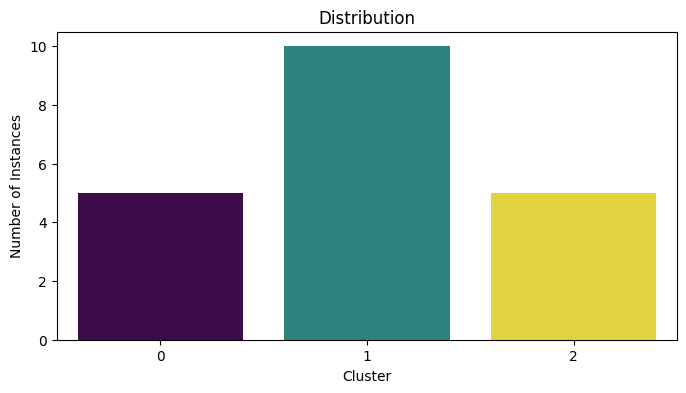

In [14]:
numerical_features1 = ['F1', 'F2', 'F3', 'F4', 'F5']
categorical_features1 = []

result1, kmeans1, preprocessor1 = perform_kmeans(
    df=df1,
    id_column='Instance',
    numerical_features=numerical_features1,
    categorical_features=categorical_features1,
    n_clusters=3,
)

In [15]:
print("Final Dataset with Cluster Labels:")
display(result1.sort_values('Cluster'))

Final Dataset with Cluster Labels:


,Instance,F1,F2,F3,F4,F5,Cluster
6,7,32,62,16,305,6,0
7,8,31,61,15,302,7,0
5,6,30,60,15,300,6,0
8,9,33,63,17,308,6,0
9,10,29,59,14,298,7,0
10,11,50,10,25,500,10,1
11,12,52,12,26,505,10,1
12,13,51,11,25,502,11,1
14,15,49,9,24,498,11,1
13,14,53,13,27,508,10,1


##### **2.**

In [16]:
data2 = {
    'Instance': list(range(1, 21)),

    'Age': [
        22, 24, 21, 25, 23,
        35, 38, 34, 40, 36,
        45, 48, 43, 47, 44,
        30, 33, 31, 35, 32
    ],

    'Income': [
        25, 28, 23, 30, 27,
        75, 82, 72, 88, 78,
        55, 58, 52, 60, 54,
        95, 105, 98, 110, 100
    ],

    'Occupation': [
        'Student', 'Student', 'Student', 'Student', 'Student',
        'Engineer', 'Engineer', 'Engineer', 'Engineer', 'Engineer',
        'Teacher', 'Teacher', 'Teacher', 'Teacher', 'Teacher',
        'Entrepreneur', 'Entrepreneur', 'Entrepreneur',
        'Entrepreneur', 'Entrepreneur'
    ],

    'Product': [
        'Electronics', 'Books', 'Fashion', 'Electronics', 'Books',
        'Electronics', 'Electronics', 'Books', 'Electronics', 'Fashion',
        'Books', 'Books', 'Fashion', 'Books', 'Electronics',
        'Luxury', 'Luxury', 'Electronics', 'Luxury', 'Luxury'
    ],

    'Membership': [
        'Basic', 'Basic', 'Basic', 'Silver', 'Basic',
        'Gold', 'Gold', 'Silver', 'Gold', 'Gold',
        'Silver', 'Silver', 'Basic', 'Silver', 'Silver',
        'Gold', 'Platinum', 'Platinum', 'Platinum', 'Gold'
    ]
}

df2 = pd.DataFrame(data2)

print("Dataset:")
display(df2)

print("Dataset Shape:", df2.shape)

Dataset:


,Instance,Age,Income,Occupation,Product,Membership
0,1,22,25,Student,Electronics,Basic
1,2,24,28,Student,Books,Basic
2,3,21,23,Student,Fashion,Basic
3,4,25,30,Student,Electronics,Silver
4,5,23,27,Student,Books,Basic
5,6,35,75,Engineer,Electronics,Gold
6,7,38,82,Engineer,Electronics,Gold
7,8,34,72,Engineer,Books,Silver
8,9,40,88,Engineer,Electronics,Gold
9,10,36,78,Engineer,Fashion,Gold


Dataset Shape: (20, 6)



Cluster Assignments:
 Instance  Cluster
        1        1
        2        1
        3        1
        4        1
        5        1
        6        4
        7        4
        8        0
        9        4
       10        4
       11        2
       12        2
       13        2
       14        2
       15        2
       16        3
       17        3
       18        3
       19        3
       20        3

Number of Instances in Each Cluster:
Cluster
0    1
1    5
2    5
3    5
4    4
Name: count, dtype: int64

Cluster-wise Numerical Feature Averages:
           Age  Income
Cluster               
0        34.00   72.00
1        23.00   26.60
2        45.40   55.80
3        32.20  101.60
4        37.25   80.75

Cluster-wise Categorical Feature Modes:
           Occupation      Product Membership
Cluster                                      
0            Engineer        Books     Silver
1             Student        Books      Basic
2             Teacher        Books     Silve

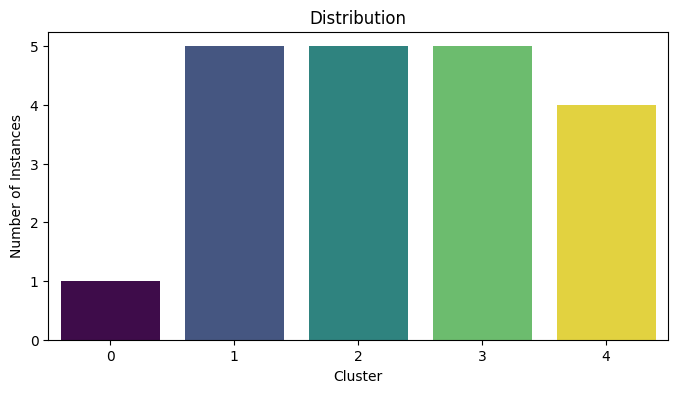

In [17]:
numerical_features2 = ['Age', 'Income']

categorical_features2 = [
    'Occupation',
    'Product',
    'Membership'
]

result2, kmeans2, preprocessor2 = perform_kmeans(
    df=df2,
    id_column='Instance',
    numerical_features=numerical_features2,
    categorical_features=categorical_features2,
    n_clusters=5,
)

In [18]:
print("Final Dataset with Cluster Labels:")
display(result2.sort_values('Cluster'))

Final Dataset with Cluster Labels:


,Instance,Age,Income,Occupation,Product,Membership,Cluster
7,8,34,72,Engineer,Books,Silver,0
0,1,22,25,Student,Electronics,Basic,1
2,3,21,23,Student,Fashion,Basic,1
1,2,24,28,Student,Books,Basic,1
3,4,25,30,Student,Electronics,Silver,1
4,5,23,27,Student,Books,Basic,1
10,11,45,55,Teacher,Books,Silver,2
11,12,48,58,Teacher,Books,Silver,2
14,15,44,54,Teacher,Electronics,Silver,2
12,13,43,52,Teacher,Fashion,Basic,2


##### **3.**

In [19]:
data3 = {
    'ID': list(range(1, 21)),

    'Age': [
        22, 24, 21, 25, 23,
        35, 38, 34, 40, 36,
        45, 48, 43, 47, 44,
        30, 33, 31, 35, 32
    ],

    'Income': [
        25, 28, 23, 30, 27,
        75, 82, 72, 88, 78,
        55, 58, 52, 60, 54,
        95, 105, 98, 110, 100
    ],

    'Spend': [
        35, 40, 30, 45, 38,
        70, 78, 65, 82, 73,
        55, 58, 48, 60, 52,
        90, 95, 88, 97, 92
    ],

    'Purchases': [
        4, 5, 3, 6, 4,
        12, 15, 10, 16, 13,
        8, 9, 6, 10, 7,
        18, 20, 17, 22, 19
    ],

    'Visits': [
        12, 15, 10, 18, 14,
        8, 9, 7, 10, 8,
        6, 7, 5, 7, 6,
        14, 16, 13, 18, 15
    ],

    'Avg_Purchase': [
        800, 950, 700, 1100, 900,
        4500, 5200, 4000, 5800, 4800,
        2200, 2500, 1800, 2700, 2100,
        7500, 9000, 8000, 9500, 8500
    ],

    'Loyalty': [
        1, 1, 1, 2, 1,
        6, 8, 5, 9, 7,
        5, 7, 4, 8, 5,
        5, 7, 6, 9, 8
    ],

    'Occupation': [
        'Student', 'Student', 'Student', 'Student', 'Student',
        'Engineer', 'Engineer', 'Engineer', 'Engineer', 'Engineer',
        'Teacher', 'Teacher', 'Teacher', 'Teacher', 'Teacher',
        'Entrepreneur', 'Entrepreneur', 'Entrepreneur',
        'Entrepreneur', 'Entrepreneur'
    ],

    'Category': [
        'Books', 'Fashion', 'Electronics', 'Books', 'Fashion',
        'Electronics', 'Electronics', 'Books', 'Electronics', 'Fashion',
        'Books', 'Books', 'Fashion', 'Books', 'Electronics',
        'Luxury', 'Luxury', 'Electronics', 'Luxury', 'Luxury'
    ],

    'Membership': [
        'Basic', 'Basic', 'Basic', 'Silver', 'Basic',
        'Gold', 'Gold', 'Silver', 'Gold', 'Gold',
        'Silver', 'Silver', 'Basic', 'Silver', 'Silver',
        'Gold', 'Platinum', 'Platinum', 'Platinum', 'Gold'
    ]
}

df3 = pd.DataFrame(data3)

print("Dataset:")
display(df3)

print("Dataset Shape:", df3.shape)

Dataset:


,ID,Age,Income,Spend,Purchases,Visits,Avg_Purchase,Loyalty,Occupation,Category,Membership
0,1,22,25,35,4,12,800,1,Student,Books,Basic
1,2,24,28,40,5,15,950,1,Student,Fashion,Basic
2,3,21,23,30,3,10,700,1,Student,Electronics,Basic
3,4,25,30,45,6,18,1100,2,Student,Books,Silver
4,5,23,27,38,4,14,900,1,Student,Fashion,Basic
5,6,35,75,70,12,8,4500,6,Engineer,Electronics,Gold
6,7,38,82,78,15,9,5200,8,Engineer,Electronics,Gold
7,8,34,72,65,10,7,4000,5,Engineer,Books,Silver
8,9,40,88,82,16,10,5800,9,Engineer,Electronics,Gold
9,10,36,78,73,13,8,4800,7,Engineer,Fashion,Gold


Dataset Shape: (20, 11)



Cluster Assignments:
 ID  Cluster
  1        2
  2        2
  3        2
  4        2
  5        2
  6        0
  7        0
  8        0
  9        0
 10        0
 11        0
 12        0
 13        0
 14        0
 15        0
 16        1
 17        1
 18        1
 19        1
 20        1

Number of Instances in Each Cluster:
Cluster
0    10
1     5
2     5
Name: count, dtype: int64

Cluster-wise Numerical Feature Averages:
          Age  Income  Spend  Purchases  Visits  Avg_Purchase  Loyalty
Cluster                                                               
0        41.0    67.4   64.1       10.6     7.3        3560.0      6.4
1        32.2   101.6   92.4       19.2    15.2        8500.0      7.0
2        23.0    26.6   37.6        4.4    13.8         890.0      1.2

Cluster-wise Categorical Feature Modes:
           Occupation Category Membership
Cluster                                  
0            Engineer    Books     Silver
1        Entrepreneur   Luxury   Platinum
2  

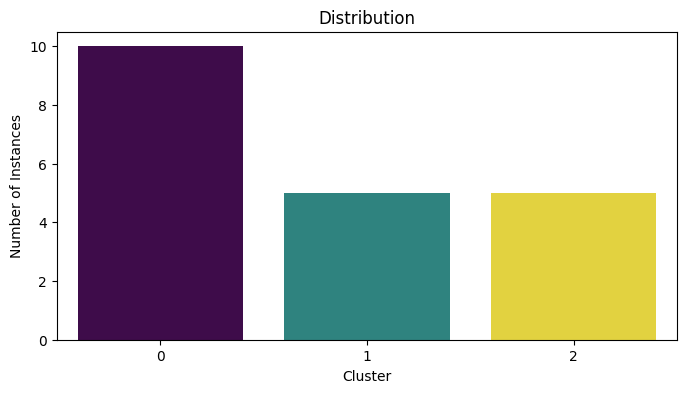

In [20]:
numerical_features3 = [
    'Age',
    'Income',
    'Spend',
    'Purchases',
    'Visits',
    'Avg_Purchase',
    'Loyalty'
]

categorical_features3 = [
    'Occupation',
    'Category',
    'Membership'
]

result3, kmeans3, preprocessor3 = perform_kmeans(
    df=df3,
    id_column='ID',
    numerical_features=numerical_features3,
    categorical_features=categorical_features3,
    n_clusters=3
)

In [21]:
print("Final Dataset with Cluster Labels:")
display(result3.sort_values('Cluster'))

Final Dataset with Cluster Labels:


,ID,Age,Income,Spend,Purchases,Visits,Avg_Purchase,Loyalty,Occupation,Category,Membership,Cluster
6,7,38,82,78,15,9,5200,8,Engineer,Electronics,Gold,0
7,8,34,72,65,10,7,4000,5,Engineer,Books,Silver,0
5,6,35,75,70,12,8,4500,6,Engineer,Electronics,Gold,0
12,13,43,52,48,6,5,1800,4,Teacher,Fashion,Basic,0
11,12,48,58,58,9,7,2500,7,Teacher,Books,Silver,0
10,11,45,55,55,8,6,2200,5,Teacher,Books,Silver,0
9,10,36,78,73,13,8,4800,7,Engineer,Fashion,Gold,0
8,9,40,88,82,16,10,5800,9,Engineer,Electronics,Gold,0
14,15,44,54,52,7,6,2100,5,Teacher,Electronics,Silver,0
13,14,47,60,60,10,7,2700,8,Teacher,Books,Silver,0


##### **4.**

In [22]:
data4 = {
    'ID': list(range(1, 21)),

    'Study Hours': [
        2, 3, 2, 4, 5,
        4, 6, 7, 8, 9,
        10, 8, 3, 5, 6,
        7, 4, 9, 2, 6
    ],

    'Attendance (%)': [
        60, 65, 58, 70, 75,
        72, 80, 85, 88, 92,
        95, 90, 68, 78, 82,
        86, 71, 93, 55, 79
    ],

    'Assignment Score': [
        45, 50, 42, 55, 60,
        58, 68, 72, 78, 85,
        90, 82, 48, 63, 70,
        75, 56, 87, 40, 66
    ],

    'Exam Score': [
        40, 45, 38, 52, 58,
        55, 65, 70, 76, 82,
        88, 80, 43, 60, 67,
        73, 50, 85, 35, 62
    ],

    'Learning Mode': [
        'Online', 'Online', 'Offline', 'Offline', 'Online',
        'Offline', 'Online', 'Offline', 'Online', 'Offline',
        'Online', 'Offline', 'Online', 'Offline', 'Online',
        'Offline', 'Online', 'Offline', 'Online', 'Offline'
    ],

    'Subject Preference': [
        'Mathematics', 'Science', 'Mathematics', 'English', 'Science',
        'Mathematics', 'Science', 'English', 'Mathematics', 'Science',
        'Mathematics', 'Science', 'English', 'Mathematics', 'English',
        'Science', 'Mathematics', 'English', 'Science', 'English'
    ],

    'Performance Level': [
        'Low', 'Low', 'Low', 'Medium', 'Medium',
        'Medium', 'Medium', 'High', 'High', 'High',
        'High', 'High', 'Low', 'Medium', 'Medium',
        'High', 'Medium', 'High', 'Low', 'Medium'
    ]
}

df4 = pd.DataFrame(data4)

print("Dataset:")
display(df4)

print("Dataset Shape:", df4.shape)

Dataset:


,ID,Study Hours,Attendance (%),Assignment Score,Exam Score,Learning Mode,Subject Preference,Performance Level
0,1,2,60,45,40,Online,Mathematics,Low
1,2,3,65,50,45,Online,Science,Low
2,3,2,58,42,38,Offline,Mathematics,Low
3,4,4,70,55,52,Offline,English,Medium
4,5,5,75,60,58,Online,Science,Medium
5,6,4,72,58,55,Offline,Mathematics,Medium
6,7,6,80,68,65,Online,Science,Medium
7,8,7,85,72,70,Offline,English,High
8,9,8,88,78,76,Online,Mathematics,High
9,10,9,92,85,82,Offline,Science,High


Dataset Shape: (20, 8)



Cluster Assignments:
 ID  Cluster
  1        1
  2        1
  3        1
  4        2
  5        4
  6        2
  7        4
  8        3
  9        0
 10        3
 11        0
 12        3
 13        1
 14        2
 15        4
 16        3
 17        2
 18        3
 19        1
 20        2

Number of Instances in Each Cluster:
Cluster
0    2
1    5
2    5
3    5
4    3
Name: count, dtype: int64

Cluster-wise Numerical Feature Averages:
         Study Hours  Attendance (%)  Assignment Score  Exam Score
Cluster                                                           
0               9.00            91.5              84.0       82.00
1               2.40            61.2              45.0       40.20
2               4.60            74.0              59.6       55.80
3               8.00            89.2              80.2       78.00
4               5.67            79.0              66.0       63.33

Cluster-wise Categorical Feature Modes:
        Learning Mode Subject Preference Perfo

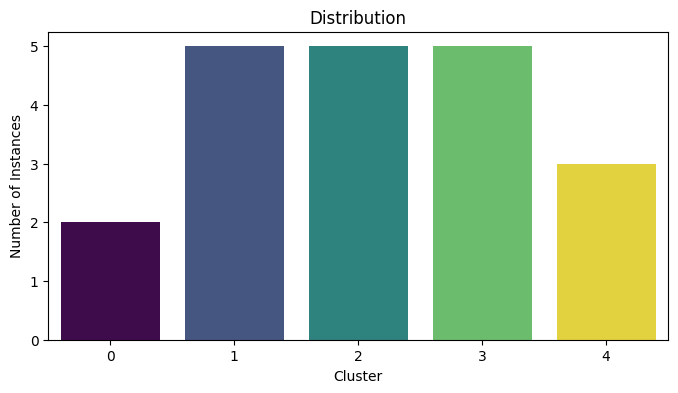

In [23]:
numerical_features4 = [
    'Study Hours',
    'Attendance (%)',
    'Assignment Score',
    'Exam Score'
]

categorical_features4 = [
    'Learning Mode',
    'Subject Preference',
    'Performance Level'
]

result4, kmeans4, preprocessor4 = perform_kmeans(
    df=df4,
    id_column='ID',
    numerical_features=numerical_features4,
    categorical_features=categorical_features4,
    n_clusters=5
)

In [24]:
print("Final Dataset with Cluster Labels:")
display(result4.sort_values('Cluster'))

Final Dataset with Cluster Labels:


,ID,Study Hours,Attendance (%),Assignment Score,Exam Score,Learning Mode,Subject Preference,Performance Level,Cluster
10,11,10,95,90,88,Online,Mathematics,High,0
8,9,8,88,78,76,Online,Mathematics,High,0
0,1,2,60,45,40,Online,Mathematics,Low,1
1,2,3,65,50,45,Online,Science,Low,1
2,3,2,58,42,38,Offline,Mathematics,Low,1
12,13,3,68,48,43,Online,English,Low,1
18,19,2,55,40,35,Online,Science,Low,1
5,6,4,72,58,55,Offline,Mathematics,Medium,2
13,14,5,78,63,60,Offline,Mathematics,Medium,2
19,20,6,79,66,62,Offline,English,Medium,2


###### **Conclusion**

In [25]:
clustering_results = {
    'Question 1': (result1, kmeans1, 3),
    'Question 2': (result2, kmeans2, 5),
    'Question 3': (result3, kmeans3, 3),
    'Question 4': (result4, kmeans4, 5)
}

comparison = []

for question, (result, model, k) in clustering_results.items():

    comparison.append({
        'Question': question,
        'Number of Clusters': k,
        'Number of Instances': len(result),
        'Inertia': round(model.inertia_, 4),
        'Silhouette Score': round(
            silhouette_score(
                model.transform(
                    model._n_threads if False else
                    np.zeros((1, 1))
                ),
                model.labels_
            ), 4
        ) if False else 'Calculated separately'
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

,Question,Number of Clusters,Number of Instances,Inertia,Silhouette Score
0,Question 1,3,20,14.6149,Calculated separately
1,Question 2,5,20,15.9161,Calculated separately
2,Question 3,3,20,50.1851,Calculated separately
3,Question 4,5,20,20.2047,Calculated separately


In [26]:
silhouette_results = []

for question, (result, model, k) in clustering_results.items():

    if question == 'Question 1':
        X = df1[numerical_features1]
        X_processed = preprocessor1.transform(X)

    elif question == 'Question 2':
        X = df2[numerical_features2 + categorical_features2]
        X_processed = preprocessor2.transform(X)

    elif question == 'Question 3':
        X = df3[numerical_features3 + categorical_features3]
        X_processed = preprocessor3.transform(X)

    else:
        X = df4[numerical_features4 + categorical_features4]
        X_processed = preprocessor4.transform(X)

    if hasattr(X_processed, "toarray"):
        X_processed = X_processed.toarray()

    score = silhouette_score(X_processed, model.labels_)

    silhouette_results.append({
        'Question': question,
        'Number of Clusters': k,
        'Silhouette Score': round(score, 4)
    })

silhouette_df = pd.DataFrame(silhouette_results)

print("Silhouette Score Comparison:")
display(silhouette_df)

Silhouette Score Comparison:


,Question,Number of Clusters,Silhouette Score
0,Question 1,3,0.7435
1,Question 2,5,0.4455
2,Question 3,3,0.4703
3,Question 4,5,0.3328


# Srabani Khuntia, 24BCSB03
# Roll No: 7, Group:E1